# Forest disturbance: expected range + flags (Belluno, Italy)

**Data:** mean Sentinel-1 **VH backscatter (dB)** over forest areas in each region, 2019–2026. Some regions only have certain months (e.g. Belluno: May–October, since snow distorts radar over forest); the model only uses the months each region actually has. This is an *indicator*, not forest-loss area.

**Why it's useful:** healthy forest gives a fairly steady VH signal each summer. If trees are blown down or cut, the signal typically **drops**. So the model learns **what normal looks like for each month**, forecasts next season's expected range, and **flags readings that fall well outside it** as possible disturbance.

**Method:**
1. Regression on each reading: a separate level for each month (May…Oct) + a slow trend across years.
2. Fit twice: first to find extreme readings, then again without them, so one odd reading can't distort "normal".
3. **Backtest:** hide the latest season, forecast it, compare with a naive guess ("same as that month last season").
4. **Forecast** next season (May–Oct) with a 95% range, and **flag** readings with robust z beyond the threshold.

## Settings

In [1]:
DATA_FILE = ["Brazil_Multi_Hazard_SAR_Flood_and_Forest_2019_2026.xlsx",
             "Vietnam_Multi_Hazard_SAR_Flood_and_Forest_2019_2026.xlsx",
             "Italy_Multi_Hazard_SAR_Flood_Forest_Subsidence_2019_2026.xlsx",
             "London_Multi_Hazard_SAR_Flood_Forest_Subsidence_2019_2026_With_Coordinates.xlsx"]
COLUMN_ALIASES = {"Average VH Backscatter (dB)": "Mean Forest VH Backscatter (dB)", "mean_vh_db": "Mean Forest VH Backscatter (dB)",
                  "date": "Observation Date", "location": "Study Area ID",
                  "Forest Coverage (Fraction)": "coverage", "Forest Coverage (0–1)": "coverage", "coverage_fraction": "coverage"}
REGION_RENAME = {"Epping Forest": "GBR_EPPING_FOREST"}
QUALITY_COL = "Quality Pass — Use for Forecasting"     # if a file has it, keep only rows marked True
SHEET     = "Forest Disturbance"
REGION_COL, DATE_COL = "Study Area ID", "Observation Date"
VALUE_COL = "Mean Forest VH Backscatter (dB)"
Z_FLAG    = 4               # robust z beyond this = flagged reading
OUTPUT_FILE = "forest_forecast.json"
LABEL = "VH forest backscatter indicator (dB), expected range; drops may indicate disturbance"

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (10, 3.5)

files = DATA_FILE if isinstance(DATA_FILE, list) else [DATA_FILE]
def read_one(f):
    df = pd.read_excel(f, sheet_name=SHEET)
    df = df.rename(columns={k: v for k, v in COLUMN_ALIASES.items() if k in df.columns and v not in df.columns})
    if QUALITY_COL in df.columns:
        df = df[df[QUALITY_COL].astype(str).str.lower().isin(["true", "1", "yes"])]
    df[REGION_COL] = df[REGION_COL].replace(REGION_RENAME)
    return df
raw = pd.concat([read_one(f) for f in files], ignore_index=True)
raw[DATE_COL] = pd.to_datetime(raw[DATE_COL])
raw = raw.dropna(subset=[VALUE_COL])
if "coverage" in raw.columns:      # several partial scenes on one day: keep the one covering the most forest
    raw = raw.sort_values("coverage", ascending=False).drop_duplicates([REGION_COL, DATE_COL])
raw = raw.sort_values(DATE_COL)
coord_tables = []
for f in files:
    try:
        coord_tables.append(pd.read_excel(f, sheet_name="Map Coordinates").dropna(subset=["South Boundary"]))
    except Exception:
        pass
coords = pd.concat(coord_tables).drop_duplicates("Study Area ID").set_index("Study Area ID") if coord_tables else None
print(raw.shape)
print(raw.groupby(REGION_COL)[DATE_COL].agg(["min", "max", "count"]))

(959, 48)
                              min        max  count
Study Area ID                                      
BRA_PORTO_VELHO_FOREST 2019-01-11 2026-11-13    303
GBR_EPPING_FOREST      2019-05-01 2026-10-28    198
ITA_BELLUNO_FOREST     2019-05-06 2026-10-27    201
VNM_BINH_PHUOC_FOREST  2019-01-01 2026-11-09    257


## 1. The model

`design()` builds one column per season month (a "dummy": 1 if the reading is in that month, else 0) plus a trend column (years since the start). Least squares then finds each month's normal level and the trend.

In [3]:
def design(dates, months, t0):
    X = [(dates.dt.month == m).astype(float).to_numpy() for m in months]
    X.append(((dates - t0).dt.days / 365.25).to_numpy())
    return np.column_stack(X)

def robust_sd(r):
    return np.median(np.abs(r - np.median(r))) * 1.4826

def fit(df, months, t0):
    X, y = design(df[DATE_COL], months, t0), df[VALUE_COL].to_numpy()
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ beta
    z = (r - np.median(r)) / robust_sd(r)
    keep = np.abs(z) <= Z_FLAG                       # second pass without extreme readings
    beta, *_ = np.linalg.lstsq(X[keep], y[keep], rcond=None)
    r = y - X @ beta
    sd = robust_sd(r[keep])
    cov = sd ** 2 * np.linalg.pinv(X[keep].T @ X[keep])
    z = (r - np.median(r[keep])) / sd
    return {"beta": beta, "sd": sd, "cov": cov, "z": z, "months": months, "t0": t0}

def predict(m, dates):
    X = design(pd.Series(dates), m["months"], m["t0"])
    mean = X @ m["beta"]
    se = np.sqrt(m["sd"] ** 2 + np.einsum("ij,jk,ik->i", X, m["cov"], X))
    return mean, mean - 1.96 * se, mean + 1.96 * se

## 2. Backtest, fit, forecast, flag

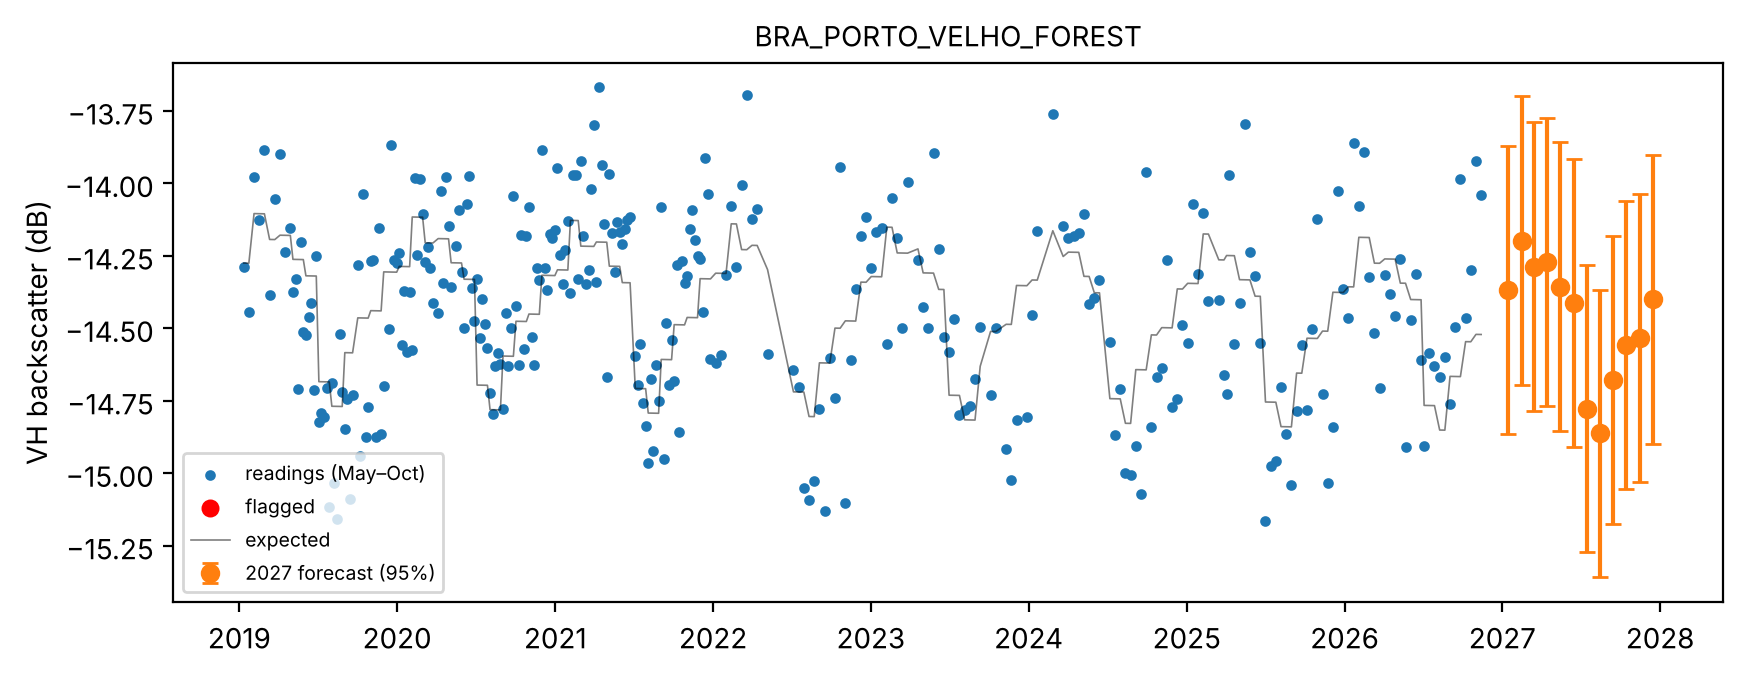

BRA_PORTO_VELHO_FOREST: trend -0.012 dB/yr (95% CI -0.024 to +0.001) | backtest MAE 0.255 vs naive 0.265 -> skill +0.04 | flagged: 0
Empty DataFrame
Columns: [Observation Date, Mean Forest VH Backscatter (dB), z]
Index: []


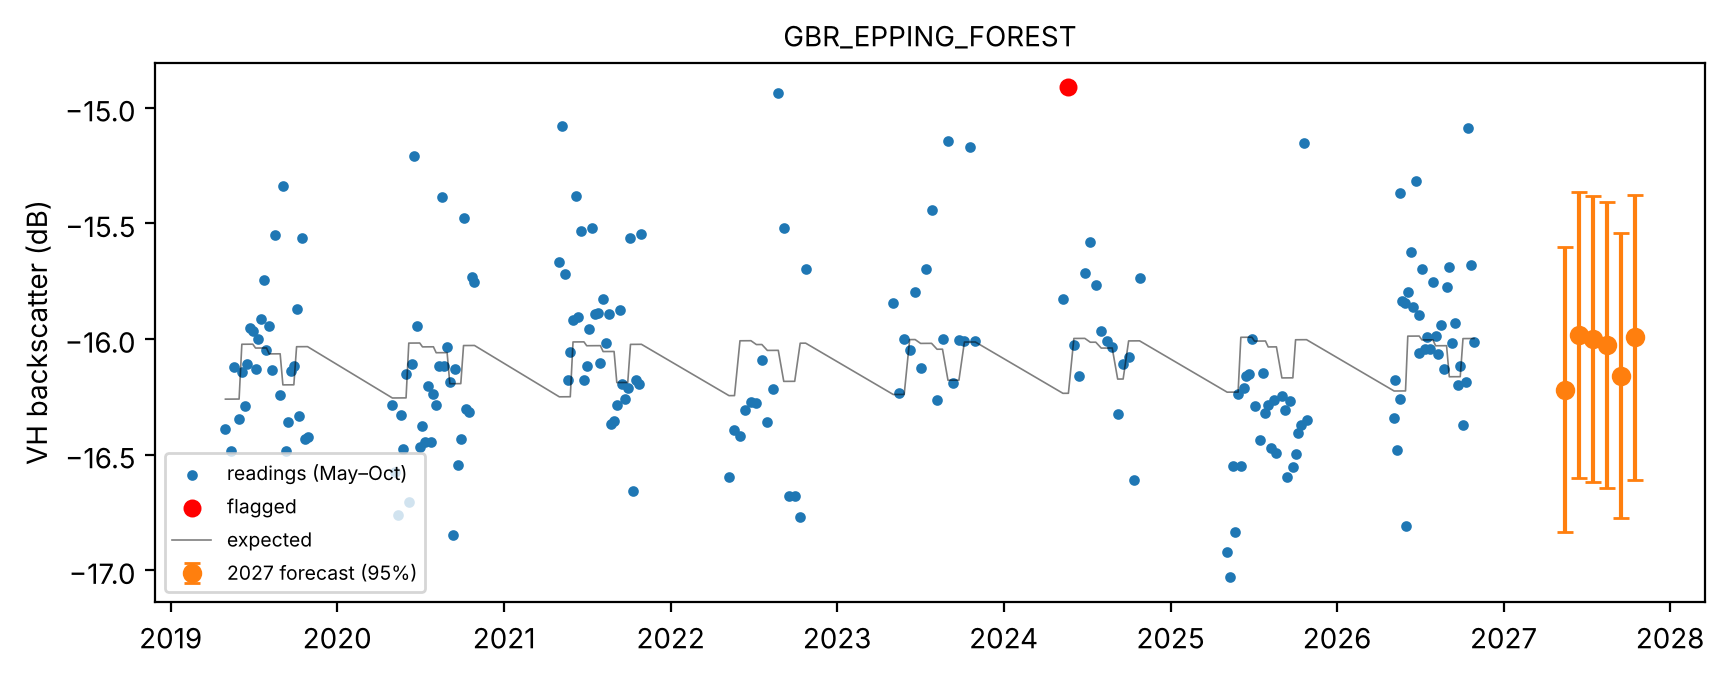

GBR_EPPING_FOREST: trend +0.005 dB/yr (95% CI -0.012 to +0.022) | backtest MAE 0.316 vs naive 0.454 -> skill +0.30 | flagged: 1
Observation Date  Mean Forest VH Backscatter (dB)   z
      2024-05-22                       -14.911751 4.4


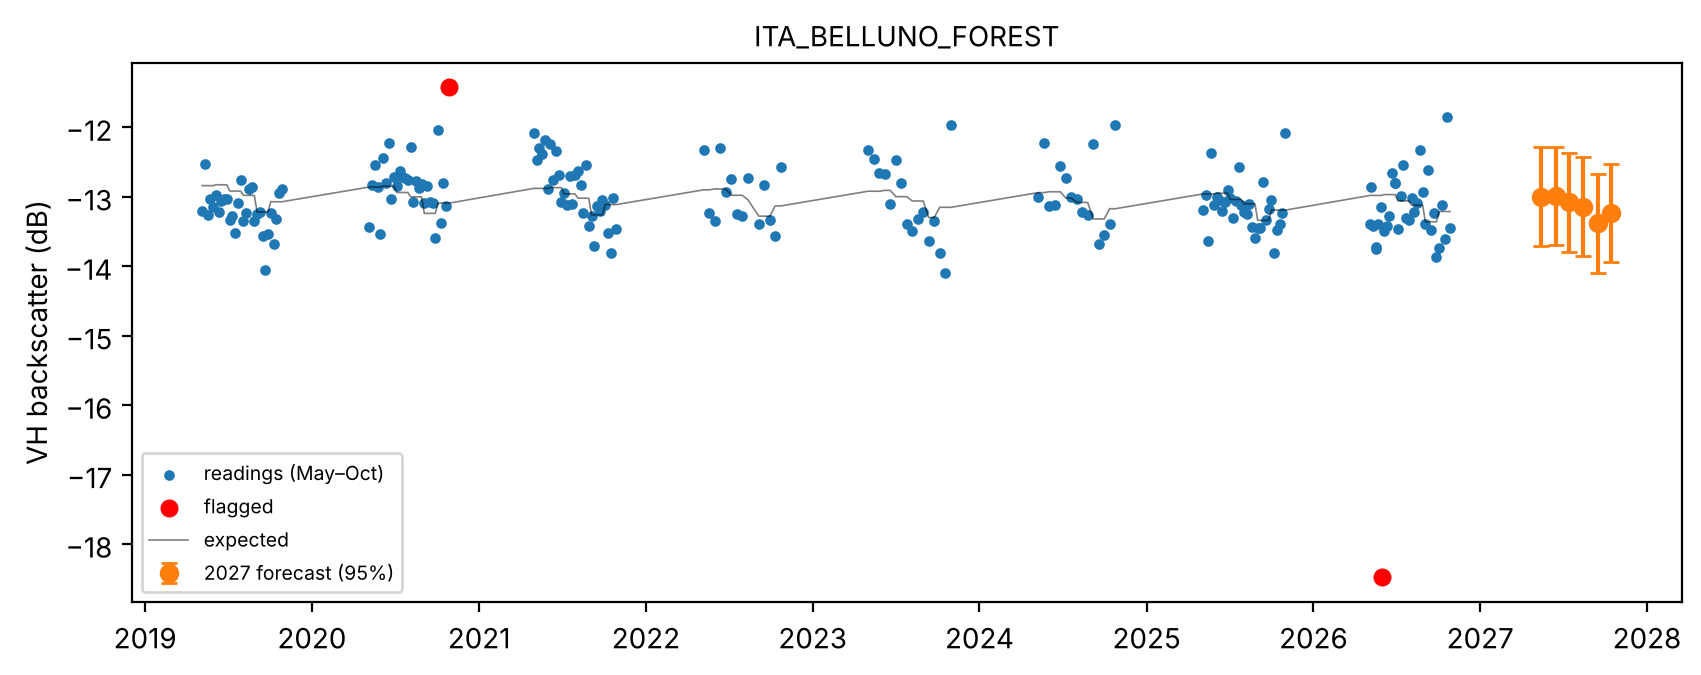

ITA_BELLUNO_FOREST: trend -0.020 dB/yr (95% CI -0.040 to -0.001) | backtest MAE 0.388 vs naive 0.378 -> skill -0.03 | flagged: 2
Observation Date  Mean Forest VH Backscatter (dB)     z
      2020-10-27                       -11.425536   4.8
      2026-05-30                       -18.480162 -15.4


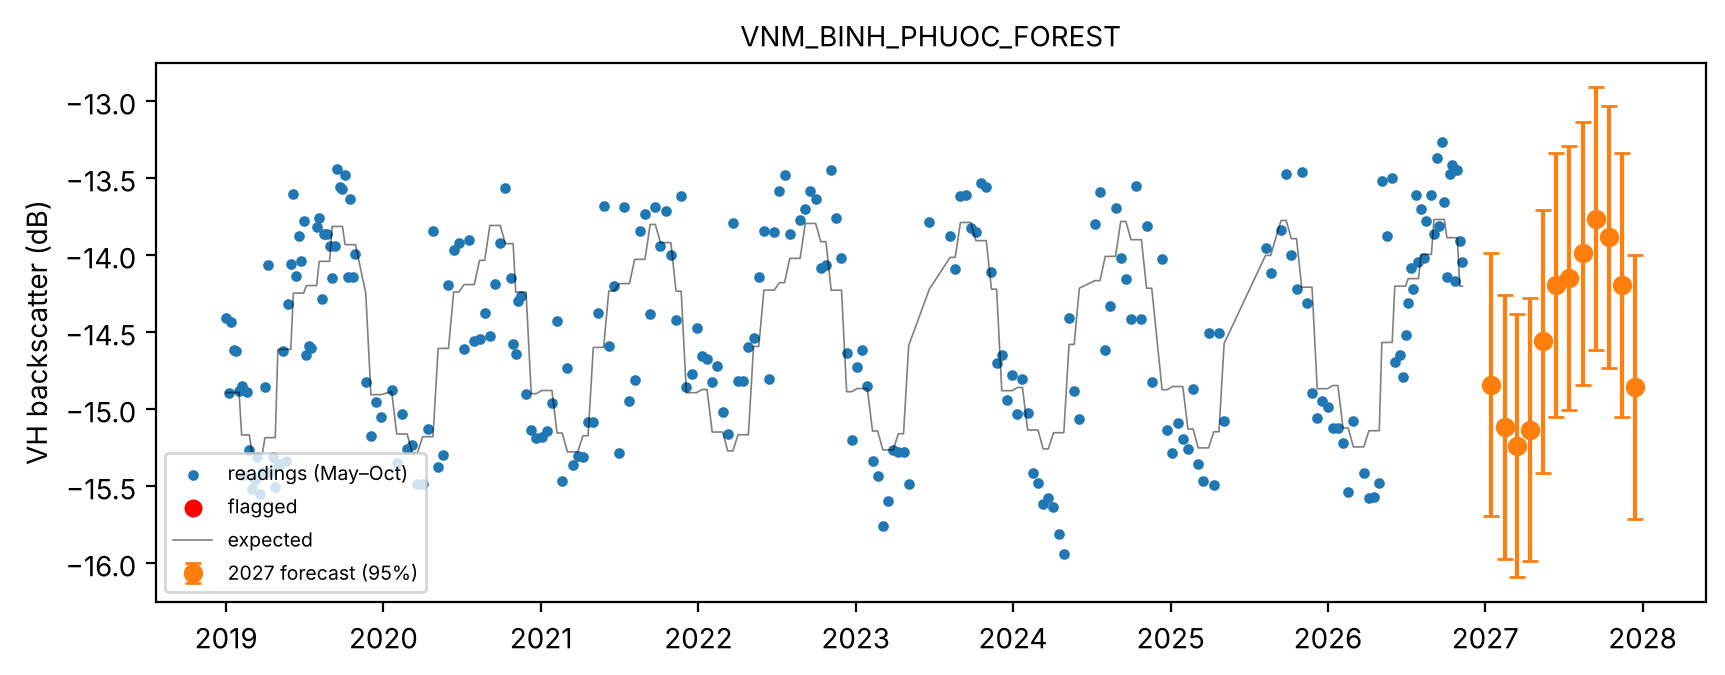

VNM_BINH_PHUOC_FOREST: trend +0.006 dB/yr (95% CI -0.015 to +0.027) | backtest MAE 0.398 vs naive 0.418 -> skill +0.05 | flagged: 0
Empty DataFrame
Columns: [Observation Date, Mean Forest VH Backscatter (dB), z]
Index: []
Wrote forest_forecast.json


In [4]:
out = {"label": LABEL, "units": "dB",
       "caveat": "Indicator over a fixed 2021 forest mask, May–October only. Not mapped forest loss; flags are candidates to check (snow, moisture or processing can also cause drops).",
       "generated": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "regions": {}}

for region, df in raw.groupby(REGION_COL):
    df = df.reset_index(drop=True)
    months = sorted(df[DATE_COL].dt.month.unique())
    t0 = df[DATE_COL].min()

    # backtest: hide the latest season
    last_year = df[DATE_COL].dt.year.max()
    train, test = df[df[DATE_COL].dt.year < last_year], df[df[DATE_COL].dt.year == last_year]
    m_bt = fit(train, months, t0)
    pred_bt = predict(m_bt, test[DATE_COL])[0]
    prev = train[train[DATE_COL].dt.year == last_year - 1].groupby(train[DATE_COL].dt.month)[VALUE_COL].mean()
    naive = test[DATE_COL].dt.month.map(prev).to_numpy()
    ok = ~np.isnan(naive)
    keep_bt = np.abs(fit(df, months, t0)["z"][df[DATE_COL].dt.year == last_year]) <= Z_FLAG   # score on non-extreme readings
    sel = ok & keep_bt.to_numpy() if hasattr(keep_bt, "to_numpy") else ok & keep_bt
    mae_model = float(np.mean(np.abs(test[VALUE_COL].to_numpy()[sel] - pred_bt[sel])))
    mae_naive = float(np.mean(np.abs(test[VALUE_COL].to_numpy()[sel] - naive[sel])))

    m = fit(df, months, t0)
    flagged = np.abs(m["z"]) > Z_FLAG

    next_year = last_year + 1
    f_dates = pd.to_datetime([f"{next_year}-{mo:02d}-15" for mo in months])
    f_mean, f_lo, f_hi = predict(m, f_dates)

    # plot
    plt.scatter(df[DATE_COL], df[VALUE_COL], s=8, label="readings (May–Oct)")
    plt.scatter(df[DATE_COL][flagged], df[VALUE_COL][flagged], c="r", s=30, zorder=3, label="flagged")
    fm, flo, fhi = predict(m, df[DATE_COL])
    plt.plot(df[DATE_COL], fm, c="k", lw=0.6, alpha=0.5, label="expected")
    plt.errorbar(f_dates, f_mean, yerr=[f_mean - f_lo, f_hi - f_mean], fmt="o", c="C1", capsize=3, label=f"{next_year} forecast (95%)")
    plt.title(region, fontsize=10); plt.ylabel("VH backscatter (dB)"); plt.legend(fontsize=7, loc="lower left"); plt.show()

    trend = m["beta"][-1]; trend_se = np.sqrt(m["cov"][-1, -1])
    print(f"{region}: trend {trend:+.3f} dB/yr (95% CI {trend - 1.96*trend_se:+.3f} to {trend + 1.96*trend_se:+.3f}) | "
          f"backtest MAE {mae_model:.3f} vs naive {mae_naive:.3f} -> skill {1 - mae_model/mae_naive:+.2f} | flagged: {int(flagged.sum())}")
    print(df.loc[flagged, [DATE_COL, VALUE_COL]].assign(z=np.round(m["z"][flagged], 1)).to_string(index=False))

    loc = None
    if coords is not None and region in coords.index:
        c = coords.loc[region]
        loc = {"centre": {"lat": float(c["Centre Latitude"]), "lon": float(c["Centre Longitude"])},
               "bounds": {"south": float(c["South Boundary"]), "west": float(c["West Boundary"]),
                          "north": float(c["North Boundary"]), "east": float(c["East Boundary"])}}
    out["regions"][region] = {
        "location": loc,
        "history": [{"date": f"{d:%Y-%m-%d}", "db": round(float(v), 3), "expected": round(float(e), 3),
                     "z": round(float(z), 2), "flagged": bool(fl)}
                    for d, v, e, z, fl in zip(df[DATE_COL], df[VALUE_COL], fm, m["z"], flagged)],
        "events": [{"date": f"{d:%Y-%m-%d}", "db": round(float(v), 3), "z": round(float(z), 2),
                    "direction": "drop (possible disturbance)" if z < 0 else "rise"}
                   for d, v, z in zip(df[DATE_COL][flagged], df[VALUE_COL][flagged], m["z"][flagged])],
        "forecast": [{"month": f"{d:%Y-%m}", "mean": round(float(a), 3), "lower": round(float(b), 3), "upper": round(float(c_), 3)}
                     for d, a, b, c_ in zip(f_dates, f_mean, f_lo, f_hi)],
        "trend_db_per_year": {"estimate": round(float(trend), 4),
                              "ci95": [round(float(trend - 1.96 * trend_se), 4), round(float(trend + 1.96 * trend_se), 4)]},
        "backtest": {"held_out_season": int(last_year), "mae_model": round(mae_model, 3), "mae_naive": round(mae_naive, 3),
                     "skill": round(1 - mae_model / mae_naive, 3) if mae_naive > 0 else None},
        "model": "month-of-season levels + linear trend (robust two-pass least squares)",
    }

with open(OUTPUT_FILE, "w") as f:
    json.dump(out, f, indent=1)
print("Wrote", OUTPUT_FILE)